# Objetivos 1 y 2

## Objetivo 1: Simular la amortización de préstamos bajo diferentes sistemas, concretamente francés y alemán, eligiendo el método con el que se va a continuar el proceso.


Cargamos las librerias

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Vamos a leer el CSV que hemos filtrado previamente

In [38]:
df = pd.read_csv("Data/df_filtrado.csv")

In [39]:
df

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Fiador,Impago,Prima,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,0.0,0,65.85,0,1,0,0,0,0,1
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,0.0,0,260.60,0,0,1,0,1,0,0
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,1.0,0,221.02,0,0,1,0,1,0,0
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,0.0,0,125.00,0,0,1,0,1,0,0
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,0.0,0,800.00,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101881,5PM51H,29,35671.0,5681,628,27.0,2,12.11,48.0,0.10,...,1.0,0,116.89,0,0,1,0,0,0,1
101882,L0RUJT,28,22864.0,40000,752,9.0,2,10.77,48.0,0.55,...,0.0,0,607.55,0,0,1,0,1,0,0
101883,8OJZU0,35,69159.0,41795,699,65.0,2,10.41,36.0,0.29,...,0.0,0,406.82,0,0,0,1,0,0,1
101884,II8B24,39,68375.0,21847,722,170.0,2,6.26,36.0,0.14,...,1.0,0,125.32,0,0,1,0,1,0,0


Monto_Inicial = capital inicial del préstamo

Ratio_Interes = tipo de interés

Duracion = duración del préstamo

In [40]:
df[["Monto_Inicial", "Ratio_Interes", "Duracion"]].head(10)

,Monto_Inicial,Ratio_Interes,Duracion
0,10000,8.96,48.0
1,16474,14.07,36.0
2,40770,12.66,12.0
3,36707,8.96,24.0
4,86981,10.07,48.0
5,63406,9.83,60.0
6,3146,16.61,36.0
7,98937,7.45,48.0
8,117341,3.46,12.0
9,40000,6.48,60.0


como vemos tenemos el interes en porcentajes por lo que el la funcion lo vamos a pasar a decimal

In [41]:
def amortizacion_francesa(df):

    capital = df["Monto_Inicial"]
    interes = df["Ratio_Interes"] / 100 #dividimos entre 100 porque tenemos el interes en porcentaje
    duracion = df["Duracion"]
    interes_mensual = interes / 12

    cuota = (capital * interes_mensual) / (1 - (1 + interes_mensual)**(-duracion))

    return cuota

Hemos creado una funcion que calcula la formula de la capitalizacion francesa 

In [42]:
df["Cuota_Francesa"] = amortizacion_francesa(df)

creamos una columna que se llame cuota francesa y llamamos a la función para meterla

In [43]:
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Impago,Prima,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Cuota_Francesa
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,0,65.85,0,1,0,0,0,0,1,248.660533
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,0,260.60,0,0,1,0,1,0,0,563.602524
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,0,221.02,0,0,1,0,1,0,0,3634.965055
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,0,125.00,0,0,1,0,1,0,0,1676.276241
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,0,800.00,0,0,1,0,0,0,1,2208.988068


In [44]:
def amortizacion_alemana(df):

    capital = df["Monto_Inicial"]
    interes = df["Ratio_Interes"] / 100
    intereses_mensuales = interes/12
    duracion = df["Duracion"]

    amortizacion = capital / duracion

    intereses = capital * intereses_mensuales

    cuota = amortizacion + intereses

    return cuota

In [45]:
df["Cuota_Alemana"] = amortizacion_alemana(df)

In [46]:
df

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Prima,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Cuota_Francesa,Cuota_Alemana
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,65.85,0,1,0,0,0,0,1,248.660533,283.000000
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,260.60,0,0,1,0,1,0,0,563.602524,650.768761
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,221.02,0,0,1,0,1,0,0,3634.965055,3827.623500
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,125.00,0,0,1,0,1,0,0,1676.276241,1803.537267
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,800.00,0,0,1,0,0,0,1,2208.988068,2542.019725
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101881,5PM51H,29,35671.0,5681,628,27.0,2,12.11,48.0,0.10,...,116.89,0,0,1,0,0,0,1,149.909528,175.684925
101882,L0RUJT,28,22864.0,40000,752,9.0,2,10.77,48.0,0.55,...,607.55,0,0,1,0,1,0,0,1029.358794,1192.333333
101883,8OJZU0,35,69159.0,41795,699,65.0,2,10.41,36.0,0.29,...,406.82,0,0,0,1,0,0,1,1356.666630,1523.543847
101884,II8B24,39,68375.0,21847,722,170.0,2,6.26,36.0,0.14,...,125.32,0,0,1,0,1,0,0,667.204825,720.829628


Para determinar la eleccion de cuota de amortizacion vamos a utilizar las variables ratio_deuda_ingresos, que corresponde a la deuda del prestatario en comparación con sus
ingresos y una variable que vamos a crear combinando dos que ya tenemos (cuota alemana y ingresos totales)

In [47]:
df["Ingresos_mensuales"] = df["Ingresos"]/14

Hemos dividido entre 14 en vez de entre 12 porque los españoles tienen derecho como minimo a dos pagas extra, según el Boletín Oficial del Estado y la mayoria recibe sus ingresos
en 14 cuotas (una por cada mes y las dos pagas extra mínimas)

dividimos la cuota alemana entre los ingresos mensuales lo que nos va a dar como resultado un valor que nos representa que esfuerzo supone para el cliente la primera cuota
de amortizacion alemana, cuanto mayor sea el valor de la columna "Ratio_Aleman" más esfuerzo supondra para el cliente

In [48]:
df["Ratio_aleman"]=( df["Cuota_Alemana"] / df["Ingresos_mensuales"])

In [49]:
df["Ratio_Deuda_Ingresos"].describe()

count    101886.000000
mean          0.321375
std           0.181194
min           0.100000
25%           0.140000
50%           0.290000
75%           0.550000
max           0.550000
Name: Ratio_Deuda_Ingresos, dtype: float64

Con los datos que tenemos vamos a calcular un ratio de endeudamiento si utilizaramos la amortizacion alemana para cada cliente, esto lo vamos a hacer sumando el ratio de deuda ingresos (DTI) y el Ratio Aleman. Esta operacion tiene sentido porque ambos se calculan igual

### Ratio de deuda ingresos = Pagos mensuales de deuda / Ingresos mensuales

### Ratio Aleman = Cuota Alemana/ Ingresos mensuales

Entonces la suma de estos nos va a dar el ratio de endeudamiento que tendria el cliente tras aplicarle la amortizacion alemana 



In [50]:
df["Ratio_Deuda_Ingresos_Aleman"] = (df["Ratio_aleman"] + df["Ratio_Deuda_Ingresos"])

In [51]:
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Cuota_Francesa,Cuota_Alemana,Ingresos_mensuales,Ratio_aleman,Ratio_Deuda_Ingresos_Aleman
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,0,0,0,0,1,248.660533,283.000000,1142.857143,0.247625,0.567625
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,1,0,1,0,0,563.602524,650.768761,2736.285714,0.237829,0.437829
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,1,0,1,0,0,3634.965055,3827.623500,3662.214286,1.045166,1.405166
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,1,0,1,0,0,1676.276241,1803.537267,2280.214286,0.790951,1.110951
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,1,0,0,0,1,2208.988068,2542.019725,1955.214286,1.300123,1.850123


El Banco de España indica que el porcentaje de ingresos netos que pueden ser destinados a las deudas nunca debe de sobrepasar el 40% de los ingresos, por lo que vamos a coger ese valor como límite. Es decir si la variable Ratio_Deuda_Ingresos_Aleman supera los 0.40 supondremos que utilizando el sistema Aleman el cliente sobrepasaria el limite recomendado por el Banco de España y entonces seleccionaremos el sistema Francés

In [52]:
df["Sistema_Elegido"] = np.where(df["Ratio_Deuda_Ingresos_Aleman"] > 0.40,"Frances","Aleman")

In [53]:
df["Sistema_Elegido"].value_counts()

Sistema_Elegido
Frances    74549
Aleman     27337
Name: count, dtype: int64

In [54]:
conteo = df["Sistema_Elegido"].value_counts()

porcentaje = conteo / len(df) * 100

print(porcentaje)

Sistema_Elegido
Frances    73.169032
Aleman     26.830968
Name: count, dtype: float64


Los resultados obtenidos tienen sentido, ya que el 73,17 % de los préstamos se han asignado al sistema frances, frente al 26,83 % al sistema aleman. Esto es coherente con nuestro criterio, puesto que el sistema aleman tiene una cuota inicial más elevada y, por tanto, es más probable que el cliente supere el límite del 40 % del ratio deuda ingresos. Por ello, resulta lógico que el sistema frances sea seleccionado para un mayor número de clientes.

## Objetivo 2: Calcular el valor presente de las cuotas pendientes a mitad del préstamo con el método seleccionado

Vamos a calcular una variable llamada mitad de prestamo para determinar en que momento del prestamo hay que calcular el valor de las cuotas, tambien vamos a crear otra que se llame cuotas pendientes que nos digar cuantas cuotas nos quedan pendientes en esa mitad del prestamos

primero vamos a comprobar que la viariable duracion en meses solo contiene meses pares

In [55]:
df["Duracion"].unique()

array([48., 36., 12., 24., 60.])

In [56]:
df["Mitad_Prestamo"] = df["Duracion"] / 2
df["Cuotas_Pendientes"] = df["Duracion"] - df["Mitad_Prestamo"]

In [57]:
def valor_presente(df):
    capital = df["Monto_Inicial"]
    interes = df["Ratio_Interes"] / 100
    intereses_mensuales = interes / 12
    duracion = df["Duracion"]
    pagado = df["Mitad_Prestamo"]
    Capital_amortizado = capital/duracion

    if df["Sistema_Elegido"] == "Frances":
        saldo_pendiente = capital*(((1 + intereses_mensuales)**duracion - (1 + intereses_mensuales)**pagado) / ((1 + intereses_mensuales)**duracion -1) )
    elif df["Sistema_Elegido"] == "Aleman":
        saldo_pendiente = capital-(pagado*Capital_amortizado)
    return saldo_pendiente




In [58]:
df["Saldo_Pendiente"] = df.apply(valor_presente, axis=1)

In [59]:
df.head(50)

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Estado_Civil_Soltero,Cuota_Francesa,Cuota_Alemana,Ingresos_mensuales,Ratio_aleman,Ratio_Deuda_Ingresos_Aleman,Sistema_Elegido,Mitad_Prestamo,Cuotas_Pendientes,Saldo_Pendiente
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,1,248.660533,283.000000,1142.857143,0.247625,0.567625,Frances,24.0,24.0,5445.153952
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,0,563.602524,650.768761,2736.285714,0.237829,0.437829,Frances,18.0,18.0,9097.996675
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,0,3634.965055,3827.623500,3662.214286,1.045166,1.405166,Frances,6.0,6.0,21026.593666
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,0,1676.276241,1803.537267,2280.214286,0.790951,1.110951,Frances,12.0,12.0,19172.138765
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,1,2208.988068,2542.019725,1955.214286,1.300123,1.850123,Frances,24.0,24.0,47837.159576
5,F9YNI5,54,44800.0,63406,642,359.0,2,9.83,60.0,0.38,...,0,1341.892530,1576.167483,3200.000000,0.492552,0.872552,Frances,30.0,30.0,35563.386181
6,98XK3H,31,19639.0,3146,688,106.0,2,16.61,36.0,0.10,...,0,111.553804,130.934772,1402.785714,0.093339,0.193339,Aleman,18.0,18.0,1573.000000
7,AKMVZ2,41,38641.0,98937,765,306.0,2,7.45,48.0,0.55,...,0,2389.880107,2675.421375,2760.071429,0.969330,1.519330,Frances,24.0,24.0,53135.769881
8,XWXHI1,45,40023.0,117341,735,260.0,3,3.46,12.0,0.55,...,0,9962.647832,10116.749883,2858.785714,3.538828,4.088828,Frances,6.0,6.0,59177.256980
9,BJ8987,31,48248.0,40000,819,19.0,1,6.48,60.0,0.47,...,0,782.271265,882.666667,3446.285714,0.256121,0.726121,Frances,30.0,30.0,21612.136410


## Cuadros de Amortizaciones completos + Comprobacion del Objetivo 2

Vamos a realizar un funcion que cree cuadros de amortizaciones completos, Además estos cuadros de amortizacion completos nos van a ayudar a ver si la columna que hemos creado para el objetivo dos "Saldo_Pendiente" es correcta o no.

In [60]:
def cuadro_amortizacion(capital, interes_anual, duracion, sistema="Frances"):
    i = interes_anual / 100 / 12 
    saldo = capital
    filas = []
    duracion = int(duracion)

    if sistema == "Frances":
        cuota = capital * i / (1 - (1 + i) ** (-duracion)) #en el frances la cuota es constante por lo que la calculamos solo una vez
    else:
        amort = capital / duracion #en el aleman la amortizacion es constante por lo que la calculamos solo una vez

    for n in range(1, duracion + 1): #n va a representar el periodo en el que estamos
        intereses = saldo * i
        if sistema == "Frances":
            amort = cuota - intereses
        else:
            cuota = amort + intereses
        saldo = saldo - amort 
        filas.append([n, cuota, intereses, amort, saldo])  # guardamos los datos del mes


    # convertimos la lista de filas en un DataFrame, que es el cuadro de amortización

    df_completo =  pd.DataFrame(filas, columns=["Periodo", "Cuota", "Intereses", "Amortizacion", "Saldo_Pendiente"])

    return df_completo

Ahora vamos a comprobar que la funcion funciona cogiendo un ejemplo de amortizacion alemana y un ejemplo de amortizacion francesa

In [61]:
ejemplo_frances = df[df["Sistema_Elegido"] == "Frances"].iloc[0] #cogemos el primer prestamo del df al que le hemos asignado la amortización francesa 
ejemplo_aleman = df[df["Sistema_Elegido"] == "Aleman"].iloc[0]  #cogemos el primer prestamo del df al que le hemos asignado la amortización alemana

#llamamos a la funcion en cada caso

cuadro_fr = cuadro_amortizacion(ejemplo_frances["Monto_Inicial"], ejemplo_frances["Ratio_Interes"], ejemplo_frances["Duracion"], "Frances")
cuadro_al = cuadro_amortizacion(ejemplo_aleman["Monto_Inicial"], ejemplo_aleman["Ratio_Interes"], ejemplo_aleman["Duracion"], "Aleman")

display(cuadro_fr)

,Periodo,Cuota,Intereses,Amortizacion,Saldo_Pendiente
0,1,248.660533,74.666667,173.993867,9.826006e+03
1,2,248.660533,73.367512,175.293021,9.650713e+03
2,3,248.660533,72.058658,176.601876,9.474111e+03
3,4,248.660533,70.740031,177.920503,9.296191e+03
4,5,248.660533,69.411557,179.248976,9.116942e+03
5,6,248.660533,68.073165,180.587368,8.936354e+03
6,7,248.660533,66.724779,181.935754,8.754419e+03
7,8,248.660533,65.366326,183.294208,8.571124e+03
8,9,248.660533,63.997729,184.662804,8.386462e+03
9,10,248.660533,62.618913,186.041620,8.200420e+03


In [62]:
display(cuadro_al)

,Periodo,Cuota,Intereses,Amortizacion,Saldo_Pendiente
0,1,130.934772,43.545883,87.388889,3.058611e+03
1,2,129.725164,42.336275,87.388889,2.971222e+03
2,3,128.515556,41.126668,87.388889,2.883833e+03
3,4,127.305949,39.917060,87.388889,2.796444e+03
4,5,126.096341,38.707452,87.388889,2.709056e+03
5,6,124.886733,37.497844,87.388889,2.621667e+03
6,7,123.677125,36.288236,87.388889,2.534278e+03
7,8,122.467517,35.078628,87.388889,2.446889e+03
8,9,121.257909,33.869020,87.388889,2.359500e+03
9,10,120.048301,32.659413,87.388889,2.272111e+03


Entonces si hemos calculado todo bien, cuando el periodo en los ejemplos sea igual al de "Mitad_prestamo" que hemos nombrado arriba el saldo pendiente del cuadro tiene que ser igual al saldo pendiente del ejemplo en el df

In [63]:
cuadro_fr[cuadro_fr["Periodo"] == ejemplo_frances["Mitad_Prestamo"]]

,Periodo,Cuota,Intereses,Amortizacion,Saldo_Pendiente
23,24,248.660533,42.198731,206.461802,5445.153952


In [64]:
ejemplo_frances["Saldo_Pendiente"]

np.float64(5445.153952018351)

In [65]:
cuadro_al[cuadro_al["Periodo"] == ejemplo_aleman["Mitad_Prestamo"]]

,Periodo,Cuota,Intereses,Amortizacion,Saldo_Pendiente
17,18,110.371438,22.98255,87.388889,1573.0


In [66]:
ejemplo_aleman["Saldo_Pendiente"]

np.float64(1573.0)

## Extra: Gráficos explicativos


Vamos a realizar unos graficos que nos ayuden a entender lo realizado hasta ahora

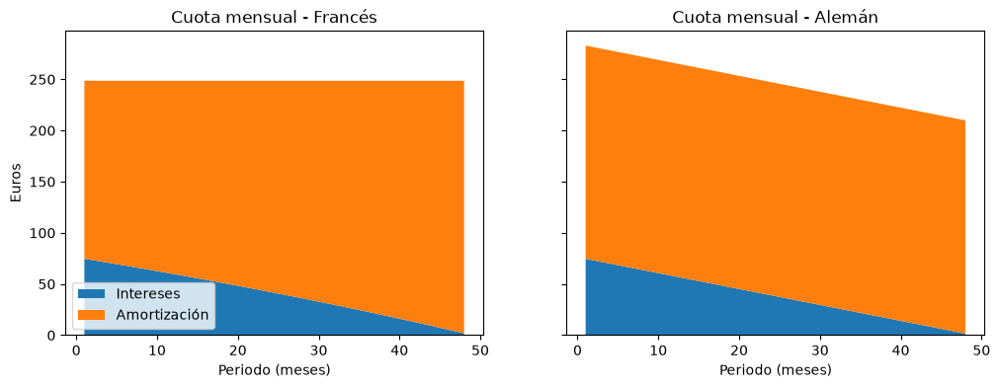

In [67]:
p = ejemplo_frances  #cogemos un prestamo y le mandamos a la funcion que hemos creado que nos haga su cuadro frances y su cuadro aleman
cuadro_fr = cuadro_amortizacion(p["Monto_Inicial"], p["Ratio_Interes"], p["Duracion"], "Frances")
cuadro_al = cuadro_amortizacion(p["Monto_Inicial"], p["Ratio_Interes"], p["Duracion"], "Aleman")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, cuadro, titulo in zip(ax, [cuadro_fr, cuadro_al], ["Francés", "Alemán"]):
    a.stackplot(cuadro["Periodo"], cuadro["Intereses"], cuadro["Amortizacion"], labels=["Intereses", "Amortización"])
    a.set_title(f"Cuota mensual - {titulo}")
    a.set_xlabel("Periodo (meses)")
ax[0].set_ylabel("Euros")
ax[0].legend(loc="lower left")
plt.show()

Como se puede apreciar en este grafico la amortizacion es constante en el sistema de amortizacion frances mientras que en el aleman comienza siendo más alta al principio y lñuego disminuye considerablemente, ademas aunque en este gráfico no se aprecie perfectamente los intereses que se pagan en el aleman son menores que los que se pagan en el frances

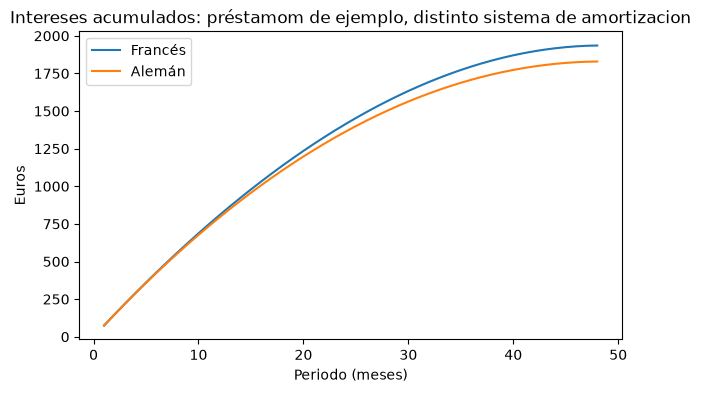

In [68]:
plt.figure(figsize=(7, 4))
plt.plot(cuadro_fr["Periodo"], cuadro_fr["Intereses"].cumsum(), label="Francés")
plt.plot(cuadro_al["Periodo"], cuadro_al["Intereses"].cumsum(), label="Alemán")
plt.title("Intereses acumulados: préstamom de ejemplo, distinto sistema de amortizacion")
plt.xlabel("Periodo (meses)")
plt.ylabel("Euros")
plt.legend()
plt.show()

Aqui hacemos que se aprecie mejor esa diferencia que hay entre los intereses que se pagan en el aleman y en el frances

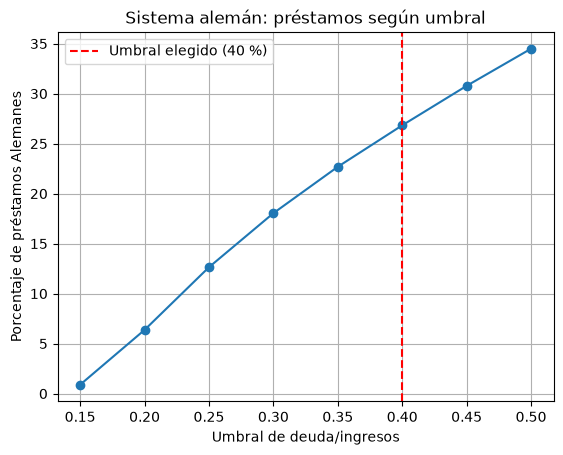

In [69]:
umbrales = [0.15, 0.20,0.25,0.30, 0.35, 0.40, 0.45, 0.50]
porcentajes = []

for umbral in umbrales:
    pct_aleman = (df["Ratio_Deuda_Ingresos_Aleman"] <= umbral).mean() * 100
    porcentajes.append(pct_aleman)

plt.plot(umbrales, porcentajes, marker="o")

plt.xlabel("Umbral de deuda/ingresos")
plt.ylabel("Porcentaje de préstamos Alemanes")
plt.title("Sistema alemán: préstamos según umbral")
plt.axvline(0.40, color="red", linestyle="--", label="Umbral elegido (40 %)")
plt.legend()

plt.xticks(umbrales)
plt.grid(True)
plt.show()

El gráfico muestra que el porcentaje de préstamos asignados al sistema alemán crece de forma gradual con el umbral, sin saltos bruscos. como hemos visto antes el 26,8 % de los préstamos pasa a alemán, y variar el umbral 5 puntos solo cambia ese porcentaje en unos 4 puntos (mas o menos). Por tanto, el criterio no es sensible a pequeñas variaciones de umbral

',ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Posesion_Hipoteca,Personas_Cargo,Fiador,Impago,Prima,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Cuota_Francesa,Cuota_Alemana,Ingresos_mensuales,Ratio_aleman,Ratio_Deuda_Ingresos_Aleman,Sistema_Elegido,Mitad_Prestamo,Cuotas_Pendientes,Saldo_Pendiente\r\n0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,0,1.0,1.0,0.0,0,65.85,0,1,0,0,0,0,1,248.66053341739126,283.0,1142.857142857143,0.24762499999999998,0.567625,Frances,24.0,24.0,5445.153952018351\r\n1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.2,2,1.0,1.0,0.0,0,260.6,0,0,1,0,1,0,0,563.6025237529393,650.7687611111111,2736.285714285714,0.2378292433840335,0.4378292433840335,Frances,18.0,18.0,9097.996674531565\r\n2,5P9OVL,51,51271.0,40770,812,309.0,1,1